# Robotaxi city-entry and fleet-allocation toy experiment (ER-SAA / ER-DRO, CVaR type)

One-to-one correspondence with the equations in the write-up (two-stage ER-DRO model, demand-function section). **Flat structure: every cell runs once from top to bottom**, and all variables are global, so anything can be inspected from any cell.

| Cell | What it does | Equation in write-up |
|---|---|---|
| 0 | Packages, real ACS zero-vehicle household shares, common functions (sigma, logit) | - |
| 1 | Candidate-city inputs x_c, M_c, kappa_c, qbar_c, F0 | notation |
| 2 | True model, evaluation scenarios D_eval, total fleet Q | (sigmoid) |
| 3 | Training-data generator -> logit OLS (learn f) -> scenario generator | (ols), (resid), (scen) |
| 4 | ER-DRO MILP (extensive form), L-shaped (decomposition), OOS evaluation | (4a)-(4h), (5), (3) |
| 5 | Learn f: for each N build beta_hat, eps_hat, D_cs and store them | - |
| 6 | Experiment loop -> `results` list | - |
| 7 | (optional) extensive form vs. decomposition | - |
| 8 | Save results CSV, figures | - |

Colab: Runtime -> Run all (about 4 min). Cell 7 runs only when `RUN_COMPARE=True`.


## 0. Packages, real ACS data, common functions

```
toy_experiment.py  (v2: real ACS zero-vehicle household shares; c+ = 1 fixed / c- varied)
=====================================================================
Toy experiment for the robotaxi city-entry and fleet-allocation problem.

Overall flow (equation numbers refer to the write-up)
  [1] candidate-city inputs          : C, x_c (real ACS), M_c, kappa_c, qbar_c, F_c, Q, c+, c-
  [2] training data from true model  : p = sigma(beta0 + beta1*x + eps)        ... eq. (sigmoid)
  [3] logit OLS regression -> beta_hat, residuals eps_hat                       ... eq. (ols), (resid)
  [4] scenario generation p_c^s, D_c^s = M_c p_c^s                              ... eq. (scen)
  [5] solve the ER-DRO (CVaR-type) MILP                                         ... eq. (4a)-(4h), variant (5)
  [6] out-of-sample cost on evaluation scenarios drawn from the true model
  [7] experiment loop over (N, zeta, c-) -> result table CSV + figures

Symbol map (code variable = symbol in write-up)
  x_c      : zero-vehicle household share of city c (context). ACS 2019-2023 5-year, table B08201, county-level actual values
  M_c      : potential trip opportunities of city c (trips/year). In the toy, proportional to ACS household count
  kappa_c  : trips one vehicle can serve per year
  qbar_c   : per-city vehicle cap
  F_c      : fixed entry cost of a city
  Q        : total fleet size
  c_plus   : loss per trip of surplus capacity (c+). Fixed at 1 here
  c_minus  : opportunity loss per unmet trip (c-). Varied over {1, 5, 10} -> c+:c- = 1:1, 1:5, 1:10
  zeta     : CVaR tail fraction. 0 gives ER-SAA (sample average)
  B        : (variant) number of cities that may be entered. None = base model with F_c y_c in the objective
  beta0, beta1, sigma_eps : coefficients and error s.d. of the true model
  N        : number of training observations = number of scenarios |S|

Required packages: numpy, scipy (>=1.9, milp/HiGHS), matplotlib
```


In [1]:
!pip -q install 'scipy>=1.11' matplotlib

import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds
import csv

rng = np.random.default_rng(2026)   # fixed random seed (reproducibility)

In [2]:
# Source: U.S. Census Bureau, ACS 2019-2023 5-year, table B08201 (queried from the Esri Living Atlas
#         "ACS Vehicle Availability Variables - Boundaries", County layer, as of 2026-10).
# Values: (county name, GEOID, total households B08201_001E, zero-vehicle household share % B08201_calc_pctNoVehE)
# City -> county mapping simplified to one central county (e.g. Phoenix -> Maricopa). New York = New York County (Manhattan) only.
ACS_NO_VEHICLE = {
    # --- current robotaxi markets (Waymo/Zoox/Tesla, 01_robotaxi_companies_markets.tex) ---
    "Phoenix":        ("Maricopa County, AZ",      "04013", 1697342,  5.1),
    "San Francisco":  ("San Francisco County, CA", "06075",  362650, 29.9),
    "Los Angeles":    ("Los Angeles County, CA",   "06037", 3390254,  8.7),
    "Austin":         ("Travis County, TX",        "48453",  561491,  5.8),
    "Atlanta":        ("Fulton County, GA",        "13121",  457791, 10.0),
    "Miami":          ("Miami-Dade County, FL",    "12086",  964805,  9.7),
    "Dallas":         ("Dallas County, TX",        "48113",  971690,  6.8),
    "Houston":        ("Harris County, TX",        "48201", 1728103,  6.8),
    "Nashville":      ("Davidson County, TN",      "47037",  314578,  6.6),
    "Orlando":        ("Orange County, FL",        "12095",  508907,  5.4),
    "San Antonio":    ("Bexar County, TX",         "48029",  740402,  6.3),
    "Las Vegas":      ("Clark County, NV",         "32003",  847378,  7.6),
    # --- Waymo future candidate markets ---
    "Baltimore":      ("Baltimore city, MD",       "24510",  250608, 26.6),
    "Boston":         ("Suffolk County, MA",       "25025",  322184, 31.8),
    "Charlotte":      ("Mecklenburg County, NC",   "37119",  455494,  5.7),
    "Chicago":        ("Cook County, IL",          "17031", 2084578, 18.0),
    "Denver":         ("Denver County, CO",        "08031",  329578, 10.3),
    "Detroit":        ("Wayne County, MI",         "26163",  693446, 11.8),
    "Minneapolis":    ("Hennepin County, MN",      "27053",  534573,  8.9),
    "New Orleans":    ("Orleans Parish, LA",       "22071",  155060, 17.1),
    "New York":       ("New York County, NY",      "36061",  775376, 77.7),
    "Philadelphia":   ("Philadelphia County, PA",  "42101",  669222, 27.8),
    "Pittsburgh":     ("Allegheny County, PA",     "42003",  546507, 12.5),
    "Portland":       ("Multnomah County, OR",     "41051",  347392, 12.7),
    "Sacramento":     ("Sacramento County, CA",    "06067",  568223,  6.4),
    "San Diego":      ("San Diego County, CA",     "06073", 1159822,  5.4),
    "Seattle":        ("King County, WA",          "53033",  927817, 11.0),
    "St. Louis":      ("St. Louis city, MO",       "29510",  144450, 17.9),
    "Tampa":          ("Hillsborough County, FL",  "12057",  569998,  5.8),
    "Washington DC":  ("District of Columbia",     "11001",  321556, 35.9),
}

CURRENT_MARKETS = ["Phoenix", "San Francisco", "Los Angeles", "Austin", "Atlanta", "Miami",
                   "Dallas", "Houston", "Nashville", "Orlando", "San Antonio", "Las Vegas"]
FUTURE_CANDIDATES = ["Baltimore", "Boston", "Charlotte", "Chicago", "Denver", "Detroit",
                     "Minneapolis", "New Orleans", "New York", "Philadelphia", "Pittsburgh",
                     "Portland", "Sacramento", "San Diego", "Seattle", "St. Louis", "Tampa",
                     "Washington DC"]

In [3]:
def sigma(z):
    """Sigmoid sigma(z) = 1/(1+e^{-z}). Inverse of the logit; maps any real number into (0,1)."""
    return 1.0 / (1.0 + np.exp(-z))


def logit(p):
    """logit(p) = ln(p/(1-p)). Maps a probability in (0,1) onto the whole real line."""
    return np.log(p / (1.0 - p))

## 1. Candidate-city inputs (x_c = real ACS values, M_c = households x 10, kappa_c = 8,760, qbar_c = 150, F0 = 1e5)


In [4]:
def make_cities(city_names, trips_per_household=10.0, qbar=150, F0=1.0e5):
    """
    Build the candidate-city inputs.
      x_c  : real ACS zero-vehicle household share (0-1 scale)
      M_c  : potential trip opportunities = (ACS total households) x trips_per_household (default 10).
             The constant trips_per_household is a toy assumption (with real data, replaced by method (c) of Factors of M).
      kappa_c = 8,760 (24 trips/day x 365 days, same as the large case)
      qbar_c  = qbar (per-city cap)
      F0      : reference value of the fixed entry cost, i.e. its value at c- = 1; in the experiments it is scaled with c- (see main below) / F = F0 x c-
    """
    names = list(city_names)
    x_c = np.array([ACS_NO_VEHICLE[n][3] / 100.0 for n in names])
    households = np.array([ACS_NO_VEHICLE[n][2] for n in names], dtype=float)
    M_c = households * trips_per_household
    kappa_c = np.full(len(names), 8760.0)
    qbar_c = np.full(len(names), qbar)
    F0_c = np.full(len(names), F0)
    return names, x_c, M_c, kappa_c, qbar_c, F0_c


# ---- run: candidate cities = 18 Waymo future candidates ----
names, x_c, M_c, kappa_c, qbar_c, F0_c = make_cities(FUTURE_CANDIDATES)
nC = len(names)
print(f"{nC} candidate cities. x_c range = {x_c.min():.3f} ~ {x_c.max():.3f}")
for n, x, M in zip(names, x_c, M_c):
    print(f"  {n:14s} x_c={x:.3f}  M_c={M/1e6:6.1f}M")

18 candidate cities. x_c range = 0.054 ~ 0.777
  Baltimore      x_c=0.266  M_c=   2.5M
  Boston         x_c=0.318  M_c=   3.2M
  Charlotte      x_c=0.057  M_c=   4.6M
  Chicago        x_c=0.180  M_c=  20.8M
  Denver         x_c=0.103  M_c=   3.3M
  Detroit        x_c=0.118  M_c=   6.9M
  Minneapolis    x_c=0.089  M_c=   5.3M
  New Orleans    x_c=0.171  M_c=   1.6M
  New York       x_c=0.777  M_c=   7.8M
  Philadelphia   x_c=0.278  M_c=   6.7M
  Pittsburgh     x_c=0.125  M_c=   5.5M
  Portland       x_c=0.127  M_c=   3.5M
  Sacramento     x_c=0.064  M_c=   5.7M
  San Diego      x_c=0.054  M_c=  11.6M
  Seattle        x_c=0.110  M_c=   9.3M
  St. Louis      x_c=0.179  M_c=   1.4M
  Tampa          x_c=0.058  M_c=   5.7M
  Washington DC  x_c=0.359  M_c=   3.2M


## 2. True model, evaluation scenarios, total fleet Q

The true model p = sigma(beta0 + beta1 x + eps) is **the 'real' demand law that we define**. Both the training data (cell 5) and the evaluation scenarios (here) are drawn from it. Q is set to the number of vehicles that covers 60% of expected total demand so that sum q <= Q binds.

beta1 = 0.8 is the zero-vehicle household share coefficient in Loa et al. (2026) Table 3 (0.008 per %-point, dependent variable ln(trips+1)) rescaled to the 0-1 scale. A log-linear trip model has the same form as logit(p) when p is small, so the coefficient is carried over directly. beta0, sigma_eps and the M_c proportionality constant are toy assumptions.


In [5]:
beta0, beta1, sigma_eps = -3.5, 0.8, 0.3      # beta1 = 0.8: 0.008 per %-point in Loa et al. (2026) Table 3, rescaled to the 0-1 scale

N_eval = 1000                                   # number of evaluation scenarios (fresh draws from the true model)
eps_eval = rng.normal(0.0, sigma_eps, size=N_eval) # epsilon assumed normally distributed
D_eval = M_c[:, None] * sigma(beta0 + beta1 * x_c[:, None] + eps_eval[None, :])

expected_total_demand = D_eval.sum(axis=0).mean()
Q = int(0.6 * expected_total_demand / kappa_c[0])
print(f" Q from the true model = {Q} vehicles, expected total demand = {expected_total_demand:,.0f} trips/year, per-city cap = {qbar_c[0]} vehicles")

 Q from the true model = 267 vehicles, expected total demand = 3,903,399 trips/year, per-city cap = 150 vehicles


## 3. Training-data generation -> logit OLS (learn f) -> scenario generation (function definitions)

`fit_logit_ols` is **where f is learned**: it fits z^k = logit(p^k) on x^k by least squares and returns beta0_hat, beta1_hat and the residuals eps_hat^k (eq. (ols), (resid)). `make_scenarios` turns that into per-city scenarios D_c^s (eq. (scen)).


In [6]:
def make_training_data(N, beta0, beta1, sigma_eps, x_low, x_high):
    """
    Generate 'observed city-year data' (x^k, p^k), k=1..N from the true model.
        p^k = sigma(beta0 + beta1 * x^k + eps^k),  eps^k ~ N(0, sigma_eps^2)
    x^k is drawn uniformly from the candidate-city range [x_low, x_high] (so that no extrapolation occurs).
    With real data this part is replaced by actual observations (robotaxi trips / M, ACS zero-vehicle share).
    """
    x_k = rng.uniform(x_low, x_high, size=N)
    eps_k = rng.normal(0.0, sigma_eps, size=N)
    p_k = sigma(beta0 + beta1 * x_k + eps_k)
    return x_k, p_k

In [7]:
def fit_logit_ols(x_k, p_k, delta=1e-3):
    """
    Eq. (ols), (resid) in the write-up.
    1) clip p^k to [delta, 1-delta] (logit is undefined at p = 0 or 1)
    2) z^k = logit(p^k)
    3) fit z^k = beta0 + beta1 x^k by least squares
    4) residuals eps_hat^k = z^k - (beta0_hat + beta1_hat x^k)   <- residuals on the logit scale
    """
    p_clip = np.clip(p_k, delta, 1 - delta)
    z_k = logit(p_clip)
    X = np.column_stack([np.ones_like(x_k), x_k])      # design matrix [1, x]
    beta_hat, *_ = np.linalg.lstsq(X, z_k, rcond=None)
    beta0_hat, beta1_hat = beta_hat
    eps_hat = z_k - (beta0_hat + beta1_hat * x_k)
    return beta0_hat, beta1_hat, eps_hat

In [8]:
def make_scenarios(x_c, M_c, beta0_hat, beta1_hat, eps_hat):
    """
    Eq. (scen) in the write-up. For each candidate city c, one residual = one scenario.
        p_c^s = sigma(beta0_hat + beta1_hat * x_c + eps_hat^s)
        D_c^s = M_c * p_c^s
    Returns D as a (number of cities) x (number of scenarios) matrix.
    """
    p_cs = sigma(beta0_hat + beta1_hat * x_c[:, None] + eps_hat[None, :])
    return M_c[:, None] * p_cs

## 4. Solution and evaluation functions (definitions only)

`solve_ER_DRO` = solve eq. (4a)-(4h) as one MILP (extensive form, HiGHS). `solve_L_shaped` = solve the same two-stage model by Benders decomposition. `oos_cost` = expected cost (oos_mean) and tail cost (oos_cvar, average of the worst 10%) on evaluation scenarios from the true model.


In [9]:
def solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=None):
    """
    Layout of the variable vector v (everything concatenated into one long vector):
        y_c   (nC, 0/1)          : enter city c or not
        q_c   (nC, integer)      : vehicles in city c
        O_c^s (nC*nS, >=0)       : surplus capacity
        U_c^s (nC*nS, >=0)       : unmet demand
        w^s   (nS, >=0)          : amount by which the scenario penalty exceeds tau
        tau   (1, free)          : CVaR threshold

    Objective (4a):  sum_c F_c y_c + tau + 1/(nS(1-zeta)) sum_s w^s
      - variant (5) (when B is given): drop F_c y_c and add the constraint sum_c y_c <= B
    Constraints:
      (4b) w^s - sum_c (c+ O_c^s + c- U_c^s) + tau >= 0      (per scenario)
      (4c) kappa_c q_c - O_c^s + U_c^s = D_c^s               (per city x scenario)
      (4d) q_c - qbar_c y_c <= 0                             (per city)
      (4e) sum_c q_c <= Q
    The constraint matrix is mostly zeros, so it is built as a sparse (coo) matrix: only nonzeros are recorded in three lists (row, col, value).
    """
    from scipy.sparse import coo_matrix
    nC, nS = D_cs.shape

    # ---- variable positions (indices) ----
    iy = lambda c: c
    iq = lambda c: nC + c
    iO = lambda c, s: 2 * nC + c * nS + s
    iU = lambda c, s: 2 * nC + nC * nS + c * nS + s
    iw = lambda s: 2 * nC + 2 * nC * nS + s
    itau = 2 * nC + 2 * nC * nS + nS
    nvar = itau + 1

    # ---- objective coefficients (4a) ----
    obj = np.zeros(nvar)
    if B is None:                                    # base model: entry cost in the objective
        for c in range(nC):
            obj[iy(c)] = F_c[c]
    obj[itau] = 1.0
    for s in range(nS):
        obj[iw(s)] = 1.0 / (nS * (1.0 - zeta))

    # ---- constraints: record (row, col, value) and give each row its [lb, ub] ----
    R, Cc, V, lbs, ubs = [], [], [], [], []
    def add(entries, lo, hi):
        r = len(lbs)
        for col, val in entries:
            R.append(r); Cc.append(col); V.append(val)
        lbs.append(lo); ubs.append(hi)

    # (4b) w^s - sum_c (c+ O_c^s + c- U_c^s) + tau >= 0
    for s in range(nS):
        add([(iw(s), 1.0), (itau, 1.0)] + [(iO(c, s), -c_plus) for c in range(nC)] + [(iU(c, s), -c_minus) for c in range(nC)],
            0.0, np.inf)
    # (4c) kappa_c q_c - O_c^s + U_c^s = D_c^s
    for c in range(nC):
        for s in range(nS):
            add([(iq(c), kappa_c[c]), (iO(c, s), -1.0), (iU(c, s), 1.0)], D_cs[c, s], D_cs[c, s])
    # (4d) q_c - qbar_c y_c <= 0
    for c in range(nC):
        add([(iq(c), 1.0), (iy(c), -qbar_c[c])], -np.inf, 0.0)
    # (4e) sum_c q_c <= Q
    add([(iq(c), 1.0) for c in range(nC)], -np.inf, Q)
    # (5) variant: sum_c y_c <= B
    if B is not None:
        add([(iy(c), 1.0) for c in range(nC)], -np.inf, B)

    A = coo_matrix((V, (R, Cc)), shape=(len(lbs), nvar)).tocsr()
    constraints = LinearConstraint(A, np.array(lbs), np.array(ubs))

    # ---- variable bounds and integrality (4f)-(4h) ----
    lb = np.zeros(nvar); ub = np.full(nvar, np.inf)
    integrality = np.zeros(nvar)                     # 0 = continuous, 1 = integer
    for c in range(nC):
        ub[iy(c)] = 1.0;  integrality[iy(c)] = 1     # y_c in {0,1}
        ub[iq(c)] = qbar_c[c]; integrality[iq(c)] = 1  # q_c integer, <= qbar_c
    lb[itau] = -np.inf                               # tau is a free variable

    # ---- solve with HiGHS ----
    res = milp(c=obj, constraints=constraints, bounds=Bounds(lb, ub), integrality=integrality)
    if res.status != 0:
        raise RuntimeError("MILP failed: " + res.message)

    v = res.x
    y = np.round(v[[iy(c) for c in range(nC)]]).astype(int)
    q = np.round(v[[iq(c) for c in range(nC)]]).astype(int)
    return y, q, v[itau], res.fun

In [10]:
# GOT HELP FROM AI
# Idea
#   master (stage 1):  min  sum_c F_c y_c + tau + theta
#                      s.t. (4d)-(4f),  tau >= 0,  theta >= 0,  theta >= (cuts accumulated so far)
#       theta stands in for the second-stage cost G(q,tau) := 1/(|S|(1-zeta)) * sum_s (H(q,D^s) - tau)^+.
#   subproblem (stage 2, per scenario): at the given (q_hat, tau_hat)
#       H_s = sum_c [c+ (kappa_c q_c - D_c^s)^+ + c- (D_c^s - kappa_c q_c)^+]   (closed form of eq. (3))
#       w_s = (H_s - tau_hat)^+
#   cut: G is convex and piecewise linear in (q,tau), so a supporting hyperplane from the subgradient at the current point
#        theta >= G(q_hat,tau_hat) + g_q . (q - q_hat) + g_tau (tau - tau_hat)   is added to the master.
#        g_q[c] = 1/(|S|(1-zeta)) * sum_{s: H_s > tau} dH_s/dq_c,   dH_s/dq_c = +kappa_c c+ (surplus) or -kappa_c c- (shortage)
#        g_tau  = -(#{s: H_s > tau}) / (|S|(1-zeta))
#   loop: solve master -> (q_hat,tau_hat) -> compute G and the cut in the subproblem -> add to master -> stop when UB-LB is small.
#   LB = master objective (cuts approximate from below, hence a lower bound), UB = sum F y + tau + G (actual cost)
#
#   the first master, with no cuts, returns y=q=0, tau=0, theta=0 (trivial solution).
#   Sending that to the subproblem gives the 'everything unmet' cost, and the cuts start accumulating from there.
#   The lower bound tau >= 0 loses nothing because H >= 0 implies the optimal tau (a quantile) is >= 0 (without it the first master is unbounded).

def solve_L_shaped(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=None,
                   tol=1e-6, max_iter=200, verbose=False):
    """
    multi-cut L-shaped: one theta_s per scenario, and cuts are added per scenario (much faster convergence).
      master:  min sum_c F_c y_c + tau + coef * sum_s theta_s
               s.t. (4d)-(4f), tau >= 0, theta_s >= 0,
                    theta_s >= H_s(q_hat) + g_s . (q - q_hat) - tau      (cut; valid for all (q,tau))
      Since (H_s - tau)^+ >= H_s - tau and H_s is convex in q, the cut above is always valid.
    """
    nC, nS = D_cs.shape
    coef = 1.0 / (nS * (1.0 - zeta))

    # ---- master variables: [y (nC), q (nC), tau, theta_1..theta_nS] ----
    iy = lambda c: c
    iq = lambda c: nC + c
    itau = 2 * nC
    ith = lambda s: 2 * nC + 1 + s
    nvar = 2 * nC + 1 + nS

    obj = np.zeros(nvar)
    if B is None:
        for c in range(nC):
            obj[iy(c)] = F_c[c]
    obj[itau] = 1.0
    for s in range(nS):
        obj[ith(s)] = coef

    rows, lbs, ubs = [], [], []
    for c in range(nC):                              # (4d) q_c - qbar_c y_c <= 0
        a = np.zeros(nvar); a[iq(c)] = 1.0; a[iy(c)] = -qbar_c[c]
        rows.append(a); lbs.append(-np.inf); ubs.append(0.0)
    a = np.zeros(nvar)                               # (4e) sum q <= Q
    for c in range(nC): a[iq(c)] = 1.0
    rows.append(a); lbs.append(-np.inf); ubs.append(Q)
    if B is not None:                                # (5) sum y <= B
        a = np.zeros(nvar)
        for c in range(nC): a[iy(c)] = 1.0
        rows.append(a); lbs.append(-np.inf); ubs.append(B)

    lb = np.zeros(nvar); ub = np.full(nvar, np.inf)
    integrality = np.zeros(nvar)
    for c in range(nC):
        ub[iy(c)] = 1.0; integrality[iy(c)] = 1
        ub[iq(c)] = qbar_c[c]; integrality[iq(c)] = 1

    def subproblem(q_hat):
        """Per-scenario second-stage cost H_s and its subgradient w.r.t. q (nC x nS). Closed form of eq. (3)."""
        slack = (kappa_c * q_hat)[:, None] - D_cs                    # kappa q - D
        H = (c_plus * np.maximum(slack, 0) + c_minus * np.maximum(-slack, 0)).sum(axis=0)
        dH_dq = np.where(slack > 0, kappa_c[:, None] * c_plus, -kappa_c[:, None] * c_minus)
        return H, dH_dq

    UB, LB, best, history = np.inf, -np.inf, None, []
    cut_rows, cut_lbs = [], []
    for it in range(1, max_iter + 1):
        A = np.vstack(rows + cut_rows)
        cons = LinearConstraint(A, np.array(lbs + cut_lbs), np.array(ubs + [np.inf] * len(cut_rows)))
        res = milp(c=obj, constraints=cons, bounds=Bounds(lb, ub), integrality=integrality)
        if res.status != 0:
            raise RuntimeError("master failed: " + res.message)
        v = res.x
        y_hat = np.round(v[:nC]).astype(int); q_hat = np.round(v[nC:2 * nC]).astype(int)
        tau_hat = v[itau]
        LB = res.fun

        H, dH_dq = subproblem(q_hat)
        # (given q_hat) tau can be optimized in closed form: tau* = the upper (1-zeta) quantile of H
        k = int(np.ceil(nS * (1.0 - zeta)))
        tau_star = np.sort(H)[-k]
        G = coef * np.maximum(H - tau_star, 0).sum()
        entry = 0.0 if B is not None else float((F_c * y_hat).sum())
        true_obj = entry + tau_star + G
        if true_obj < UB:
            UB = true_obj; best = (y_hat.copy(), q_hat.copy(), tau_star)
        history.append((it, LB, UB, int(q_hat.sum())))
        if verbose:
            print(f"    iter {it:3d}: LB={LB:14.1f} UB={UB:14.1f} gap={(UB-LB)/max(abs(UB),1):.2e} sum q={q_hat.sum()}")
        if UB - LB <= tol * max(abs(UB), 1.0):
            break

        # ---- per-scenario cut: theta_s - g_s.q + tau >= H_s - g_s.q_hat ----
        for s in range(nS):
            a = np.zeros(nvar)
            a[ith(s)] = 1.0
            a[itau] = 1.0
            for c in range(nC):
                a[iq(c)] = -dH_dq[c, s]
            cut_rows.append(a)
            cut_lbs.append(H[s] - float(dH_dq[:, s] @ q_hat))

    y, q, tau = best
    return y, q, tau, UB, it, history

In [11]:
def second_stage_cost(q, D_cs, kappa_c, c_plus, c_minus):
    """
    Closed form of eq. (3). Per-scenario second-stage cost H(q, D^s) for a given q and demand matrix D.
        O_c^s = (kappa_c q_c - D_c^s)^+ ,  U_c^s = (D_c^s - kappa_c q_c)^+
    """
    cap = (kappa_c * q)[:, None]
    O = np.maximum(cap - D_cs, 0.0)
    U = np.maximum(D_cs - cap, 0.0)
    return (c_plus * O + c_minus * U).sum(axis=0)


def oos_cost(y, q, D_eval, F_c, kappa_c, c_plus, c_minus, B=None, tail=0.9):
    """
    Two out-of-sample costs on evaluation scenarios D_eval freshly drawn from the true model:
      oos_mean = entry cost (base model only) + mean of the second-stage cost           (expected cost)
      oos_cvar = entry cost + mean of the top (1-tail) fraction of second-stage costs    (tail cost, CVaR_tail)
    A DRO solution with zeta>0 aims to cut the tail cost at a small loss in expected cost, so both are reported.
    """
    entry = 0.0 if B is not None else float((F_c * y).sum())
    H = second_stage_cost(q, D_eval, kappa_c, c_plus, c_minus)
    k = int(np.ceil((1.0 - tail) * len(H)))
    return entry + H.mean(), entry + np.sort(H)[-k:].mean()

## 5. Learn f

For each N in {15, 200}, generate training data, learn f and store it in `fits[N]`. After this cell f is trained, and you can check right away whether the estimated coefficients are close to the true values.


In [12]:
grid_N = [15, 200]          # number of training observations = number of scenarios |S|
fits = {}
for N in grid_N:
    x_k, p_k = make_training_data(N, beta0, beta1, sigma_eps, x_c.min(), x_c.max())
    b0_hat, b1_hat, eps_hat = fit_logit_ols(x_k, p_k)          # <- learn f
    D_cs = make_scenarios(x_c, M_c, b0_hat, b1_hat, eps_hat)   # <- candidate-city scenarios (city x scenario)
    D_nocontext = M_c[:, None] * p_k[None, :]                  # benchmark: no context, use the training p^k directly
    fits[N] = dict(x_k=x_k, p_k=p_k, b0=b0_hat, b1=b1_hat, eps=eps_hat, D_cs=D_cs, D_nocontext=D_nocontext)
    print(f"[N={N}] beta0_hat={b0_hat:.3f} (true {beta0}), beta1_hat={b1_hat:.3f} (true {beta1}), residual s.d.={eps_hat.std():.3f} (true {sigma_eps})")

[N=15] beta0_hat=-3.655 (true -3.5), beta1_hat=1.114 (true 0.8), residual s.d.=0.325 (true 0.3)
[N=200] beta0_hat=-3.479 (true -3.5), beta1_hat=0.665 (true 0.8), residual s.d.=0.298 (true 0.3)


## 6. Experiment loop

c+ = 1 fixed, c- in {1, 5, 10} (c+:c- = 1:1, 1:5, 1:10), zeta in {0, 0.5, 0.9}, benchmark (no_context), variant B in {2, 3, 5}.

One row of `results` = for one combination (method, N, c-, zeta): **the solution (y, q) chosen under that setting**, its in-sample objective, OOS expected cost and OOS tail cost.


In [13]:
c_plus = 1.0
grid_cminus = [1.0, 5.0, 10.0]
grid_zeta = [0.0, 0.5, 0.9]
scale_F_with_cminus = True    # F_c = F0 * c-  (keeps the entry-cost-to-margin ratio independent of c-)

results = []
for N in grid_N:
    D_cs, D_nocontext = fits[N]["D_cs"], fits[N]["D_nocontext"]
    for c_minus in grid_cminus:
        F_c = F0_c * (c_minus if scale_F_with_cminus else 1.0)
        for zeta in grid_zeta:
            y, q, tau, obj = solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta)
            oos, oos_cvar = oos_cost(y, q, D_eval, F_c, kappa_c, c_plus, c_minus)
            y2, q2, tau2, obj2 = solve_ER_DRO(D_nocontext, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta)
            oos2, oos2_cvar = oos_cost(y2, q2, D_eval, F_c, kappa_c, c_plus, c_minus)
            for m, yy, qq, ob, oo, oc in [("contextual", y, q, obj, oos, oos_cvar),
                                          ("no_context", y2, q2, obj2, oos2, oos2_cvar)]:
                results.append(dict(method=m, N=N, c_minus=c_minus, zeta=zeta,
                                    cities=[names[i] for i in np.where(yy == 1)[0]],
                                    total_q=int(qq.sum()), q=qq.tolist(),
                                    in_sample=ob, oos=oo, oos_cvar90=oc))
            print(f"N={N} c-={c_minus:<4} zeta={zeta:<4} | contextual entered={[names[i] for i in np.where(y==1)[0]]} "
                  f"sum q={q.sum():4d} OOS mean={oos:12.0f} OOS tail={oos_cvar:12.0f} | no_context OOS mean={oos2:12.0f}")
        for B in [2, 3, 5]:   # variant (5): limit on the number of entered cities (zeta = 0.9 example)
            y, q, tau, obj = solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, 0.9, B=B)
            oos, oos_cvar = oos_cost(y, q, D_eval, F_c, kappa_c, c_plus, c_minus, B=B)
            results.append(dict(method=f"budget_B={B}", N=N, c_minus=c_minus, zeta=0.9,
                                cities=[names[i] for i in np.where(y == 1)[0]],
                                total_q=int(q.sum()), q=q.tolist(), in_sample=obj, oos=oos, oos_cvar90=oos_cvar))
            print(f"    variant B={B}: entered={[names[i] for i in np.where(y==1)[0]]} sum q={q.sum()} OOS (second stage only)={oos:,.0f}")

N=15 c-=1.0  zeta=0.0  | contextual entered=['Chicago', 'Detroit', 'New York', 'Philadelphia', 'Pittsburgh', 'Sacramento', 'San Diego', 'Seattle', 'Tampa'] sum q= 267 OOS mean=     2695476 OOS tail=     4857473 | no_context OOS mean=     2758361
N=15 c-=1.0  zeta=0.5  | contextual entered=['Chicago', 'Detroit', 'New York', 'Philadelphia', 'San Diego', 'Seattle'] sum q= 267 OOS mean=     2724601 OOS tail=     4557473 | no_context OOS mean=     3112997
N=15 c-=1.0  zeta=0.9  | contextual entered=['Chicago', 'New York', 'San Diego', 'Seattle'] sum q= 267 OOS mean=     3147884 OOS tail=     4410069 | no_context OOS mean=     3869252
    variant B=2: entered=['Chicago', 'New York'] sum q=195 OOS (second stage only)=3,315,579
    variant B=3: entered=['Chicago', 'New York', 'San Diego'] sum q=251 OOS (second stage only)=3,084,918
    variant B=5: entered=['Chicago', 'New York', 'Philadelphia', 'San Diego', 'Seattle'] sum q=267 OOS (second stage only)=2,358,358
N=15 c-=5.0  zeta=0.0  | contex

## 7. (optional) Extensive form vs. decomposition

Set `RUN_COMPARE = True` to solve N = 15, c- = 5, zeta = 0.9 with both methods and compare objective, entered cities, time and iterations. The case with the budget constraint B = 3 is run as well, to check whether "a valid inequality / budget constraint speeds up the decomposition" (observed here: without B, 38 iterations, about 54.5 s; with B = 3, 38 iterations, 29.5 s; extensive form 0.4 s).


In [14]:
RUN_COMPARE = True
if RUN_COMPARE:
    import time
    D_cs = fits[15]["D_cs"]; c_minus = 5.0; zeta = 0.9; F_c = F0_c * c_minus
    for B in [3, None]:
        t0 = time.time(); y1, q1, tau1, obj1 = solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=B); t1 = time.time() - t0
        t0 = time.time(); y2, q2, tau2, obj2, n_it, hist = solve_L_shaped(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=B, tol=1e-2); t2 = time.time() - t0
        print(f"B={B}")
        print(f"  extensive: obj={obj1:14.1f} entered={[names[i] for i in np.where(y1==1)[0]]} sum q={q1.sum()} {t1:6.1f}s")
        print(f"  L-shaped : obj={obj2:14.1f} entered={[names[i] for i in np.where(y2==1)[0]]} sum q={q2.sum()} {t2:6.1f}s iterations={n_it} (first master sum q={hist[0][3]})")

B=3
  extensive: obj=    16036514.6 entered=['Chicago', 'New York', 'San Diego'] sum q=253    0.7s
  L-shaped : obj=    16140861.1 entered=['Chicago', 'New York', 'San Diego'] sum q=265   32.0s iterations=38 (first master sum q=0)
B=None
  extensive: obj=    17304198.3 entered=['Chicago', 'New York', 'Philadelphia', 'Seattle'] sum q=267    1.7s
  L-shaped : obj=    17378352.5 entered=['Chicago', 'Minneapolis', 'New York', 'San Diego'] sum q=267   49.5s iterations=38 (first master sum q=0)


## 8. Save results and plot


results saved: toy_results.csv


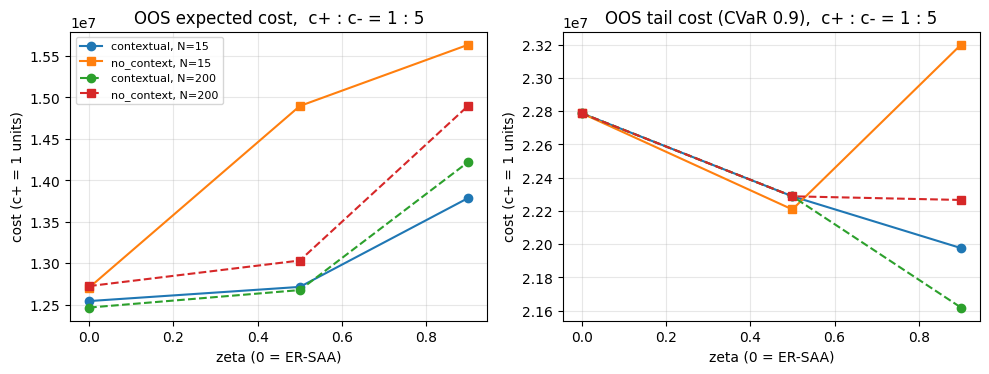

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
with open("toy_results.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(results[0].keys()))
    w.writeheader(); w.writerows(results)
print("results saved: toy_results.csv")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key, ttl in zip(axes, ["oos", "oos_cvar90"], ["OOS expected cost", "OOS tail cost (CVaR 0.9)"]):
    for N, ls in zip(grid_N, ["-", "--"]):
        for m, mk in zip(["contextual", "no_context"], ["o", "s"]):
            ys = [r[key] for r in results if r["method"] == m and r["N"] == N and r["c_minus"] == 5.0]
            ax.plot(grid_zeta, ys, ls, marker=mk, label=f"{m}, N={N}")
    ax.set_xlabel("zeta (0 = ER-SAA)"); ax.set_ylabel("cost (c+ = 1 units)")
    ax.set_title(ttl + ",  c+ : c- = 1 : 5"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig("toy_oos_vs_zeta.png", dpi=150); plt.show()

try:
    from google.colab import files
    files.download("toy_results.csv"); files.download("toy_oos_vs_zeta.png")
except ImportError:
    pass

## 9. Checking the estimate of f (counterpart of EV paper Tables 2-3, Figures 3, 8)

Four things are checked to see whether f was learned properly.

1. **Coefficients**: are beta0_hat, beta1_hat near the true values (known because this is a toy), and is the sign beta1_hat > 0 consistent with the literature (more zero-vehicle households -> higher robotaxi choice)?
2. **Fit**: train/test MSE, MAE, max error and R^2 on the p scale (EV paper Table 3 style). The test set is 1,000 fresh draws from the true model.
3. **Assumption (2)**: residual mean ~ 0, residual spread not changing with x (homoscedasticity), no skew -> can the residuals be pooled and reused as scenarios?
4. **Value of context**: test error of the model using x vs. the model ignoring x and using only the mean p (no_context).

Panels of Figure 1: (a) data, fitted line and true line on the logit scale, (b) residual histogram, (c) residual vs. x, (d) predicted p vs. true p on the test set.


Table 1. Estimate of f (logit OLS) -- error metrics on the p scale, 1,000 test observations


,beta0_hat,beta1_hat,sigma_eps_hat,residual mean,train MSE,test MSE,test MAE,test ME,test R2,no_context test MSE,no_context test R2
N,,,,,,,,,,,
15,-3.6548,1.1140,0.3246,0.0000,0.0002,0.0002,0.0101,0.0461,0.1236,0.0002,-0.0106
200,-3.4791,0.6652,0.2979,0.0000,0.0002,0.0002,0.0099,0.0479,0.1427,0.0002,-0.0126
true,-3.5000,0.8000,0.3000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


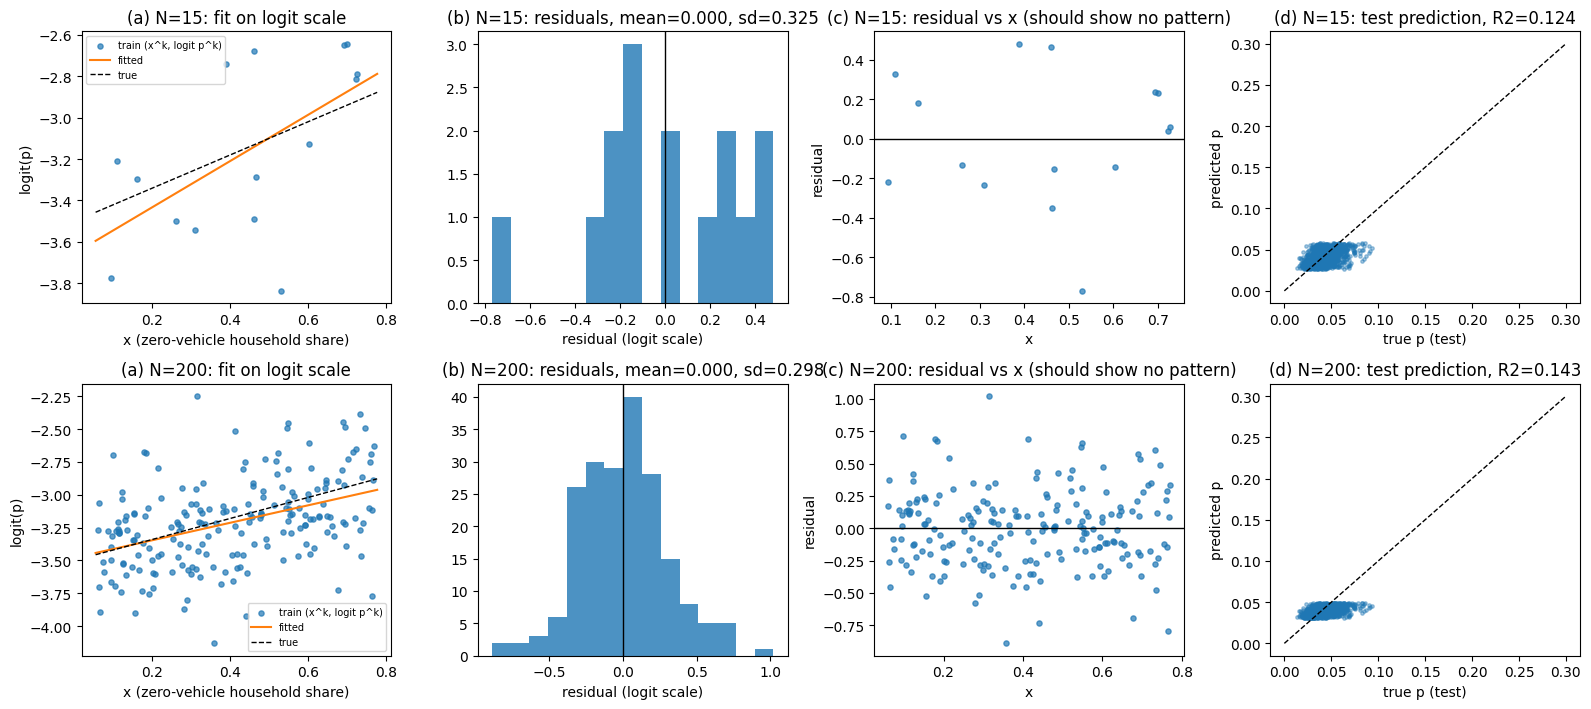

In [16]:
# ======================================================================
# 9. Diagnostics of the estimate of f (counterpart of EV paper Table 2/3, Figure 3/8)
# ======================================================================
# What is checked
#  (a) coefficients: is beta_hat near the true value (possible only in the toy), is the sign as in the literature (beta1 > 0)
#  (b) fit: train/test MSE, MAE, max error (ME), R^2  -- reported on the p scale
#  (c) assumption (2): residual mean 0, residual spread not changing with x (homoscedastic), no skew
#  (d) value of context: test error of the model using x vs. the model ignoring x and using only the mean p
import pandas as pd

def regression_diagnostics(fits, N_test=1000):
    rows = []
    x_t, p_t = make_training_data(N_test, beta0, beta1, sigma_eps, x_c.min(), x_c.max())  # test data (true model)
    for N, f in fits.items():
        x_k, p_k, b0, b1, eps = f["x_k"], f["p_k"], f["b0"], f["b1"], f["eps"]
        # predictions on the p scale
        p_hat_tr = sigma(b0 + b1 * x_k);  p_hat_te = sigma(b0 + b1 * x_t)
        p_bar = p_k.mean()                                    # benchmark (no_context): mean of the training p
        def metrics(p, ph):
            e = p - ph
            return dict(MSE=np.mean(e**2), MAE=np.mean(np.abs(e)), ME=np.max(np.abs(e)),
                        R2=1 - np.sum(e**2) / np.sum((p - p.mean())**2))
        m_tr, m_te, m_nc = metrics(p_k, p_hat_tr), metrics(p_t, p_hat_te), metrics(p_t, np.full_like(p_t, p_bar))
        rows.append({"N": N, "beta0_hat": b0, "beta1_hat": b1, "sigma_eps_hat": eps.std(),
                     "residual mean": eps.mean(),
                     "train MSE": m_tr["MSE"], "test MSE": m_te["MSE"], "test MAE": m_te["MAE"],
                     "test ME": m_te["ME"], "test R2": m_te["R2"],
                     "no_context test MSE": m_nc["MSE"], "no_context test R2": m_nc["R2"]})
    tab = pd.DataFrame(rows).set_index("N")
    tab.loc["true"] = [beta0, beta1, sigma_eps] + [np.nan] * (tab.shape[1] - 3)
    return tab, (x_t, p_t)

reg_table, (x_test, p_test) = regression_diagnostics(fits)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Table 1. Estimate of f (logit OLS) -- error metrics on the p scale, 1,000 test observations")
display(reg_table)

# ---- Figure 1: 4 panels per N ----
fig, axes = plt.subplots(len(fits), 4, figsize=(16, 3.6 * len(fits)))
xx = np.linspace(x_c.min(), x_c.max(), 100)
for r, (N, f) in enumerate(fits.items()):
    x_k, p_k, b0, b1, eps = f["x_k"], f["p_k"], f["b0"], f["b1"], f["eps"]
    z_k = logit(np.clip(p_k, 1e-3, 1 - 1e-3))
    ax = axes[r, 0]   # (a) logit scale: data, fitted line, true line
    ax.scatter(x_k, z_k, s=14, alpha=.7, label="train (x^k, logit p^k)")
    ax.plot(xx, b0 + b1 * xx, "C1", label="fitted")
    ax.plot(xx, beta0 + beta1 * xx, "k--", lw=1, label="true")
    ax.set_xlabel("x (zero-vehicle household share)"); ax.set_ylabel("logit(p)"); ax.set_title(f"(a) N={N}: fit on logit scale"); ax.legend(fontsize=7)
    ax = axes[r, 1]   # (b) residual histogram
    ax.hist(eps, bins=15, color="C0", alpha=.8); ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("residual (logit scale)"); ax.set_title(f"(b) N={N}: residuals, mean={eps.mean():.3f}, sd={eps.std():.3f}")
    ax = axes[r, 2]   # (c) residual vs x (check homoscedasticity and zero mean)
    ax.scatter(x_k, eps, s=14, alpha=.7); ax.axhline(0, color="k", lw=1)
    ax.set_xlabel("x"); ax.set_ylabel("residual"); ax.set_title(f"(c) N={N}: residual vs x (should show no pattern)")
    ax = axes[r, 3]   # (d) test: predicted p vs true p
    ax.scatter(p_test, sigma(b0 + b1 * x_test), s=6, alpha=.4)
    lim = [0, max(p_test.max(), 0.3)]; ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel("true p (test)"); ax.set_ylabel("predicted p"); ax.set_title(f"(d) N={N}: test prediction, R2={reg_table.loc[N,'test R2']:.3f}")
fig.tight_layout(); fig.savefig("fig1_f_diagnostics.png", dpi=150); plt.show()

## 10. Full result tables (counterpart of EV paper Tables 4, 8)

One row of Table 2 = one setting (N, c-, zeta): the cities entered and total fleet chosen by the contextual model, its in-sample objective, and the OOS mean / tail cost of that solution scored on 1,000 true-model scenarios. The three right-hand columns are the no-context benchmark under the same setting and the gain (%) relative to it.

Table 3 is variant (5): second-stage cost and selected cities when the number of entered cities B is limited to 2, 3, 5.


In [17]:
# ======================================================================
# 10. Full result tables (counterpart of EV paper Table 4/8)
# ======================================================================
df = pd.DataFrame(results)
df["cities"] = df["cities"].apply(lambda L: ", ".join(L))
main_df = df[df["method"].isin(["contextual", "no_context"])]
main_df = main_df.assign(zeta=main_df["zeta"].map(lambda z: f"{z:.1f}"), c_minus=main_df["c_minus"].map(lambda v: f"{v:g}"))
ctx = main_df[main_df.method == "contextual"].set_index(["N", "c_minus", "zeta"])
noc = main_df[main_df.method == "no_context"].set_index(["N", "c_minus", "zeta"])
table2 = pd.DataFrame({
    "entered cities (contextual)": ctx["cities"],
    "# entered": ctx["cities"].str.count(",") + 1,
    "sum q": ctx["total_q"],
    "in-sample": ctx["in_sample"],
    "OOS mean": ctx["oos"],
    "OOS tail (CVaR.9)": ctx["oos_cvar90"],
    "no_context OOS mean": noc["oos"],
    "no_context OOS tail": noc["oos_cvar90"],
})
table2["context gain (%)"] = 100 * (table2["no_context OOS mean"] - table2["OOS mean"]) / table2["no_context OOS mean"]
pd.set_option("display.float_format", lambda v: f"{v:,.0f}"); pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 250)
print("Table 2. Full results: optimal entry/allocation per setting and in-sample / out-of-sample cost (c+ = 1 units)")
display(table2)

bud = df[df["method"].str.startswith("budget")].copy()
bud["B"] = bud["method"].str.extract(r"(\d+)").astype(int)
table3 = bud.pivot_table(index=["N", "c_minus"], columns="B", values="oos")
table3_cities = bud.pivot_table(index=["N", "c_minus"], columns="B", values="cities", aggfunc="first")
print("\nTable 3. Variant (5): OOS second-stage cost by number of entered cities B (zeta = 0.9)"); display(table3)
print("Table 3-b. Entered cities by B"); display(table3_cities)
table2.to_csv("table2_main_results.csv", encoding="utf-8-sig"); table3.to_csv("table3_budget.csv", encoding="utf-8-sig")

Table 2. Full results: optimal entry/allocation per setting and in-sample / out-of-sample cost (c+ = 1 units)


entered cities (contextual)  # entered  sum q  in-sample   OOS mean  OOS tail (CVaR.9)  no_context OOS mean  no_context OOS tail  context gain (%)
N   c_minus zeta                                                                                                                                                                                              
15  1       0.0   Chicago, Detroit, New York, Philadelphia, Pittsburgh, Sacramento, ...          9    267  2,490,926  2,695,476          4,857,473            2,758,361            4,657,473                 2
            0.5            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle          6    267  2,864,469  2,724,601          4,557,473            3,112,997            4,357,473                12
            0.9                                   Chicago, New York, San Diego, Seattle          4    267  3,460,840  3,147,884          4,410,069            3,869,252            4,739,552                19
    5       0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle          6    267 11,386,313 12,541,832         22,787,364           12,702,986           22,787,364                 1
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle          5    267 13,635,159 12,712,913         22,287,364           14,896,198           22,208,291                15
            0.9                                Chicago, New York, Philadelphia, Seattle          4    267 17,304,198 13,787,444         21,975,797           15,636,705           23,199,859                12
    10      0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle          6    267 22,412,124 24,728,335         45,574,729           25,166,440           45,574,729                 2
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle          5    267 27,186,803 25,027,407         44,574,729           28,863,429           44,263,095                13
            0.9                             Chicago, New York, San Diego, Washington DC          4    267 34,608,397 27,416,340         43,920,442           30,089,296           45,739,579                 9
200 1       0.0   Chicago, Detroit, New York, Philadelphia, Pittsburgh, Sacramento, ...          8    267  2,599,840  2,662,764          4,757,473            2,748,503            4,657,473                 3
            0.5            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle          6    267  3,054,078  2,712,652          4,557,473            2,980,460            4,457,473                 9
            0.9                                   Chicago, New York, San Diego, Seattle          4    267  4,415,710  3,084,216          4,357,473            3,727,040            4,610,719                17
    5       0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle          6    267 12,225,772 12,463,377         22,787,364           12,722,661           22,787,364                 2
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle          5    267 14,870,099 12,674,534         22,287,364           13,031,319           22,287,364                 3
            0.9                                            Chicago, New York, San Diego          3    267 22,045,780 14,222,971         21,617,923           14,901,907           22,265,378                 5
    10      0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle          6    267 24,168,288 24,654,132         45,574,729           25,128,612           45,574,729                 2
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle          5    267 29,646,948 24,957,044         44,574,729           25,611,150           44,574,729                 3
            0.9                                            Chicago, New York, San Diego          3    267 44,013,689 27,629,179


Table 3. Variant (5): OOS second-stage cost by number of entered cities B (zeta = 0.9)


B                    2          3          5
N   c_minus                                 
15  1        3,315,579  3,084,918  2,358,358
    5       14,339,887 12,668,561 10,305,798
    10      28,111,826 24,631,627 20,068,402
200 1        3,395,462  3,198,004  2,440,092
    5       14,572,482 12,726,413 11,735,447
    10      28,274,685 24,625,772 22,821,183

Table 3-b. Entered cities by B


B                            2                             3                                                    5
N   c_minus                                                                                                      
15  1        Chicago, New York  Chicago, New York, San Diego  Chicago, New York, Philadelphia, San Diego, Seattle
    5        Chicago, New York  Chicago, New York, San Diego  Chicago, New York, Philadelphia, San Diego, Seattle
    10       Chicago, New York  Chicago, New York, San Diego  Chicago, New York, Philadelphia, San Diego, Seattle
200 1        Chicago, New York  Chicago, New York, San Diego  Chicago, Detroit, New York, Philadelphia, San Diego
    5        Chicago, New York  Chicago, New York, San Diego  Chicago, Philadelphia, Pittsburgh, San Diego, Tampa
    10       Chicago, New York  Chicago, New York, San Diego  Chicago, Philadelphia, Pittsburgh, San Diego, Tampa

## 11. Sensitivity analysis (counterpart of EV paper Figures 6, 7)

Starting from the base setting N = 200, c- = 5, c+ = 1, zeta = 0.9, change **one parameter at a time** and look at the OOS expected cost. Three lines: contextual ER-DRO (zeta = 0.9), contextual ER-SAA (zeta = 0), no_context.

Panels: F0 (entry cost), Q ratio (total fleet), qbar (city cap), kappa (trips per vehicle), c- (c+ = 1 fixed), beta1 (how strongly context drives demand - counterpart of the alpha1 sweep in the EV paper; the true model changes, so training and estimation are redone), sigma_eps (demand variability), N (training sample size), zeta (mean vs. tail trade-off).

Runtime about 15 min (about 130 solves).


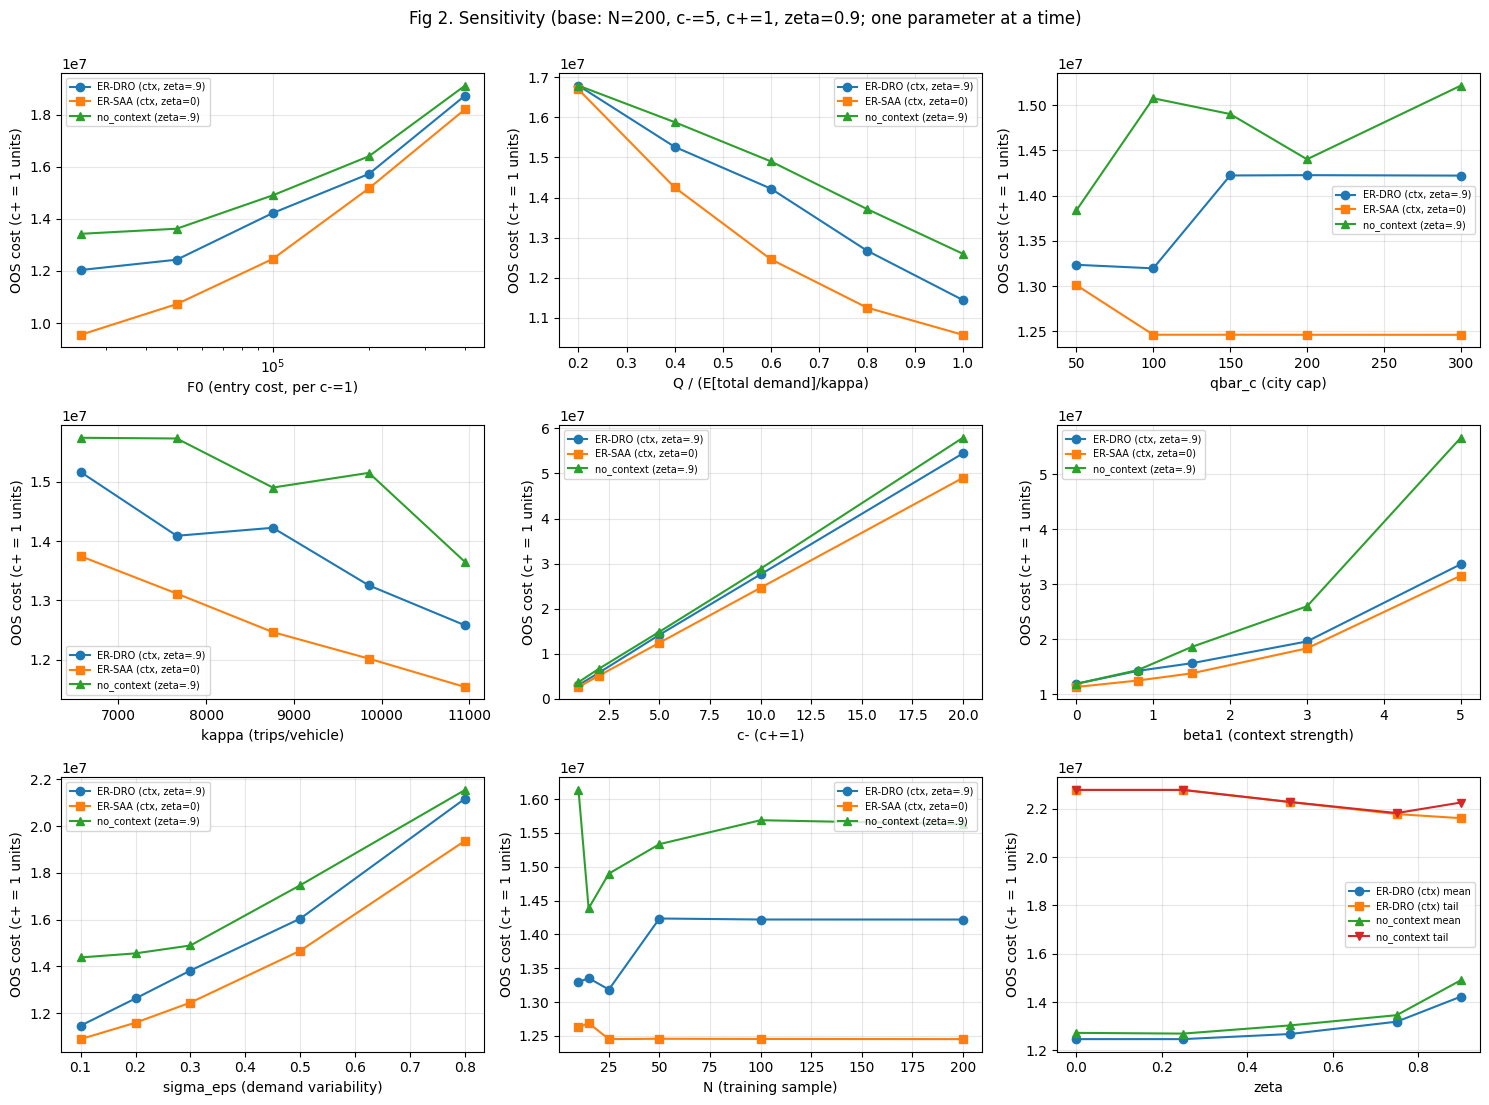

Table 4. Sensitivity analysis numbers (saved to table4_sensitivity.csv)


,parameter,value,"ER-DRO (ctx, zeta=.9)","ER-SAA (ctx, zeta=0)",no_context (zeta=.9),ER-DRO (ctx) mean,ER-DRO (ctx) tail,no_context mean,no_context tail
0,"F0 (entry cost, per c-=1)","25,000","12,035,919","9,550,795","13,424,780",NaN,NaN,NaN,NaN
1,"F0 (entry cost, per c-=1)","50,000","12,432,800","10,729,102","13,620,842",NaN,NaN,NaN,NaN
2,"F0 (entry cost, per c-=1)","100,000","14,222,971","12,463,377","14,901,907",NaN,NaN,NaN,NaN
3,"F0 (entry cost, per c-=1)","200,000","15,722,971","15,169,052","16,400,447",NaN,NaN,NaN,NaN
4,"F0 (entry cost, per c-=1)","400,000","18,726,628","18,202,394","19,109,450",NaN,NaN,NaN,NaN
5,Q / (E[total demand]/kappa),0,"16,787,334","16,691,233","16,787,334",NaN,NaN,NaN,NaN
6,Q / (E[total demand]/kappa),0,"15,263,211","14,253,088","15,878,123",NaN,NaN,NaN,NaN
7,Q / (E[total demand]/kappa),1,"14,222,971","12,463,377","14,901,907",NaN,NaN,NaN,NaN
8,Q / (E[total demand]/kappa),1,"12,678,733","11,258,250","13,715,388",NaN,NaN,NaN,NaN
9,Q / (E[total demand]/kappa),1,"11,445,299","10,578,821","12,597,833",NaN,NaN,NaN,NaN


In [18]:
# ======================================================================
# 11. Sensitivity analysis (counterpart of EV paper Figures 6, 7)
# ======================================================================
# Base setting: N = 200, c- = 5 (c+ = 1), zeta = 0.9. Change one parameter at a time and compare the OOS expected cost
#   lines: contextual ER-DRO (zeta=.9), contextual ER-SAA (zeta=0), no_context (zeta=.9)
def run_three(D_cs, D_noc, D_ev, F_c, kap, qb, Qv, cp, cm, zeta=0.9):
    out = {}
    y, q, _, _ = solve_ER_DRO(D_cs, F_c, kap, qb, Qv, cp, cm, zeta);  out["ER-DRO (ctx, zeta=.9)"] = oos_cost(y, q, D_ev, F_c, kap, cp, cm)[0]
    y, q, _, _ = solve_ER_DRO(D_cs, F_c, kap, qb, Qv, cp, cm, 0.0);   out["ER-SAA (ctx, zeta=0)"] = oos_cost(y, q, D_ev, F_c, kap, cp, cm)[0]
    y, q, _, _ = solve_ER_DRO(D_noc, F_c, kap, qb, Qv, cp, cm, zeta); out["no_context (zeta=.9)"] = oos_cost(y, q, D_ev, F_c, kap, cp, cm)[0]
    return out

base = dict(N=200, c_minus=5.0, zeta=0.9)
fb = fits[base["N"]]
sens = {}

# (a) fixed entry cost F0
sens["F0 (entry cost, per c-=1)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, np.full(nC, v) * base["c_minus"], kappa_c, qbar_c, Q, c_plus, base["c_minus"])
                          for v in [0.25e5, 0.5e5, 1e5, 2e5, 4e5]}
# (b) total fleet Q as a ratio of expected total demand
sens["Q / (E[total demand]/kappa)"] = {r: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * base["c_minus"], kappa_c, qbar_c,
                                      int(r * expected_total_demand / kappa_c[0]), c_plus, base["c_minus"])
                           for r in [0.2, 0.4, 0.6, 0.8, 1.0]}
# (c) per-city cap qbar
sens["qbar_c (city cap)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * base["c_minus"], kappa_c, np.full(nC, v), Q, c_plus, base["c_minus"])
               for v in [50, 100, 150, 200, 300]}
# (d) vehicle productivity kappa (+/-25%)
sens["kappa (trips/vehicle)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * base["c_minus"], np.full(nC, v), qbar_c, Q, c_plus, base["c_minus"])
             for v in [6570, 7665, 8760, 9855, 10950]}
# (e) c- (c+ = 1 fixed)
sens["c- (c+=1)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * v, kappa_c, qbar_c, Q, c_plus, v)
                     for v in [1, 2, 5, 10, 20]}
# (f) context strength beta1 (counterpart of the alpha1 sweep in the EV paper): the true model changes, so evaluation scenarios, training and estimation are redone
sens["beta1 (context strength)"] = {}
for b1v in [0.0, 0.8, 1.5, 3.0, 5.0]:  # 0.8 = value rescaled from Loa et al.
    D_ev = M_c[:, None] * sigma(beta0 + b1v * x_c[:, None] + eps_eval[None, :])
    Qv = int(0.6 * D_ev.sum(axis=0).mean() / kappa_c[0])
    xk, pk = make_training_data(base["N"], beta0, b1v, sigma_eps, x_c.min(), x_c.max())
    b0h, b1h, eh = fit_logit_ols(xk, pk)
    sens["beta1 (context strength)"][b1v] = run_three(make_scenarios(x_c, M_c, b0h, b1h, eh), M_c[:, None] * pk[None, :], D_ev,
                                               F0_c * base["c_minus"], kappa_c, qbar_c, Qv, c_plus, base["c_minus"])
# (g) error size sigma_eps (demand variability)
sens["sigma_eps (demand variability)"] = {}
for sv in [0.1, 0.2, 0.3, 0.5, 0.8]:
    D_ev = M_c[:, None] * sigma(beta0 + beta1 * x_c[:, None] + (eps_eval / sigma_eps * sv)[None, :])
    xk, pk = make_training_data(base["N"], beta0, beta1, sv, x_c.min(), x_c.max())
    b0h, b1h, eh = fit_logit_ols(xk, pk)
    sens["sigma_eps (demand variability)"][sv] = run_three(make_scenarios(x_c, M_c, b0h, b1h, eh), M_c[:, None] * pk[None, :], D_ev,
                                      F0_c * base["c_minus"], kappa_c, qbar_c, Q, c_plus, base["c_minus"])
# (h) training sample size N (how the value of DRO changes with N)
sens["N (training sample)"] = {}
for Nv in [10, 15, 25, 50, 100, 200]:
    xk, pk = make_training_data(Nv, beta0, beta1, sigma_eps, x_c.min(), x_c.max())
    b0h, b1h, eh = fit_logit_ols(xk, pk)
    sens["N (training sample)"][Nv] = run_three(make_scenarios(x_c, M_c, b0h, b1h, eh), M_c[:, None] * pk[None, :], D_eval,
                                       F0_c * base["c_minus"], kappa_c, qbar_c, Q, c_plus, base["c_minus"])
# (i) zeta
sens["zeta"] = {}
for zv in [0.0, 0.25, 0.5, 0.75, 0.9]:
    o = {}
    y, q, _, _ = solve_ER_DRO(fb["D_cs"], F0_c * 5, kappa_c, qbar_c, Q, c_plus, 5.0, zv); m, t = oos_cost(y, q, D_eval, F0_c * 5, kappa_c, c_plus, 5.0)
    o["ER-DRO (ctx) mean"] = m; o["ER-DRO (ctx) tail"] = t
    y, q, _, _ = solve_ER_DRO(fb["D_nocontext"], F0_c * 5, kappa_c, qbar_c, Q, c_plus, 5.0, zv); m, t = oos_cost(y, q, D_eval, F0_c * 5, kappa_c, c_plus, 5.0)
    o["no_context mean"] = m; o["no_context tail"] = t
    sens["zeta"][zv] = o

# ---- Figure 2: 3 x 3 panels ----
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, (pname, d) in zip(axes.ravel(), sens.items()):
    xs = list(d.keys()); keys = list(next(iter(d.values())).keys())
    for kname, mk in zip(keys, ["o", "s", "^", "v"]):
        ax.plot(xs, [d[x][kname] for x in xs], marker=mk, label=kname)
    ax.set_xlabel(pname); ax.set_ylabel("OOS cost (c+ = 1 units)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
    if pname.startswith("F0"): ax.set_xscale("log")
fig.suptitle("Fig 2. Sensitivity (base: N=200, c-=5, c+=1, zeta=0.9; one parameter at a time)", y=1.0)
fig.tight_layout(); fig.savefig("fig2_sensitivity.png", dpi=150); plt.show()

# ---- Table 4: sensitivity numbers ----
sens_rows = [dict(parameter=p, value=v, **o) for p, d in sens.items() for v, o in d.items()]
sens_df = pd.DataFrame(sens_rows); sens_df.to_csv("table4_sensitivity.csv", index=False, encoding="utf-8-sig")
print("Table 4. Sensitivity analysis numbers (saved to table4_sensitivity.csv)"); display(sens_df)